# Deep Learning / NLP Text Classifier

## SMS Spam Detection

### RabTech Academy AI & ML Internship — Task 5

This project implements a deep learning based NLP text classification system for detecting spam SMS messages.

The workflow includes:

- Text preprocessing
- TF-IDF vectorization
- Train/test splitting
- Multi-layer neural network
- Batch normalization
- Dropout regularization
- Early stopping
- Training and validation
- Loss and accuracy curves
- Unseen SMS prediction
- Classification confidence

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.13.0+cpu
CUDA available: False


In [3]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (5572, 2)

Column names:
['label', 'message']


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
print(df["label"].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [6]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

Before removing duplicates: (5572, 2)
After removing duplicates: (5169, 2)


In [7]:
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df.head())
print("\nLabel counts:")
print(df["label"].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Label counts:
label
0    4516
1     653
Name: count, dtype: int64


In [8]:
X = df["message"]
y = df["label"]

print("Number of messages:", len(X))
print("Number of labels:", len(y))

Number of messages: 5169
Number of labels: 5169


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4135, 5000)
Testing TF-IDF shape: (1034, 5000)


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4135, 5000)
Testing TF-IDF shape: (1034, 5000)


In [12]:
import numpy as np
import torch

X_train_array = X_train_tfidf.toarray().astype(np.float32)
X_test_array = X_test_tfidf.toarray().astype(np.float32)

y_train_array = y_train.to_numpy().astype(np.float32)
y_test_array = y_test.to_numpy().astype(np.float32)

X_train_tensor = torch.tensor(X_train_array)
X_test_tensor = torch.tensor(X_test_array)

y_train_tensor = torch.tensor(y_train_array).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test_array).reshape(-1, 1)

print("X train tensor:", X_train_tensor.shape)
print("y train tensor:", y_train_tensor.shape)

X train tensor: torch.Size([4135, 5000])
y train tensor: torch.Size([4135, 1])


In [13]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 65
Testing batches: 17


In [14]:
import torch.nn as nn

class SpamClassifier(nn.Module):

    def __init__(self, input_size):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [15]:
input_size = X_train_tensor.shape[1]

model = SpamClassifier(input_size)

print(model)

SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.2, inplace=False)
    (11): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [16]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model, loss function and optimizer are ready.")

Model, loss function and optimizer are ready.


In [17]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_tensor,
    y_train_tensor,
    test_size=0.20,
    random_state=42,
    stratify=y_train_tensor.numpy()
)

train_final_dataset = TensorDataset(
    X_train_final,
    y_train_final
)

val_dataset = TensorDataset(
    X_val,
    y_val
)

train_final_loader = DataLoader(
    train_final_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

In [18]:
epochs = 30
patience = 5

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
patience_counter = 0

for epoch in range(epochs):

    # -------------------------
    # Training
    # -------------------------

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_final_loader:

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(train_final_loader)
    train_accuracy = correct / total

    # -------------------------
    # Validation
    # -------------------------

    model.eval()

    val_loss_total = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            val_loss_total += loss.item()

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / len(val_loader)
    val_accuracy = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # -------------------------
    # Early Stopping
    # -------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "best_spam_classifier.pth"
        )

    else:

        patience_counter += 1

        if patience_counter >= patience:

            print("Early stopping triggered.")

            break

Epoch [1/30] Train Loss: 0.2764 Train Acc: 0.8912 Val Loss: 0.2407 Val Acc: 0.9008
Epoch [2/30] Train Loss: 0.0488 Train Acc: 0.9909 Val Loss: 0.0766 Val Acc: 0.9770
Epoch [3/30] Train Loss: 0.0160 Train Acc: 0.9949 Val Loss: 0.0748 Val Acc: 0.9746
Epoch [4/30] Train Loss: 0.0056 Train Acc: 0.9985 Val Loss: 0.0789 Val Acc: 0.9734
Epoch [5/30] Train Loss: 0.0047 Train Acc: 0.9994 Val Loss: 0.0745 Val Acc: 0.9770
Epoch [6/30] Train Loss: 0.0044 Train Acc: 0.9985 Val Loss: 0.0826 Val Acc: 0.9758
Epoch [7/30] Train Loss: 0.0106 Train Acc: 0.9958 Val Loss: 0.0865 Val Acc: 0.9807
Epoch [8/30] Train Loss: 0.0086 Train Acc: 0.9970 Val Loss: 0.0816 Val Acc: 0.9794
Epoch [9/30] Train Loss: 0.0090 Train Acc: 0.9979 Val Loss: 0.0725 Val Acc: 0.9794
Epoch [10/30] Train Loss: 0.0047 Train Acc: 0.9988 Val Loss: 0.0780 Val Acc: 0.9831
Epoch [11/30] Train Loss: 0.0043 Train Acc: 0.9988 Val Loss: 0.0911 Val Acc: 0.9819
Epoch [12/30] Train Loss: 0.0067 Train Acc: 0.9976 Val Loss: 0.0977 Val Acc: 0.9794
E

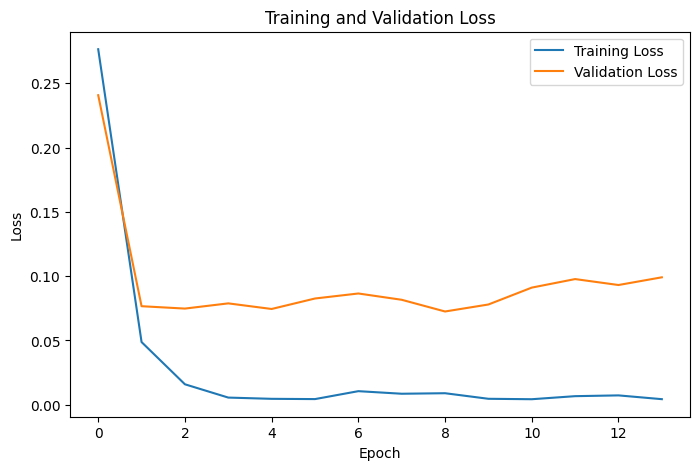

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

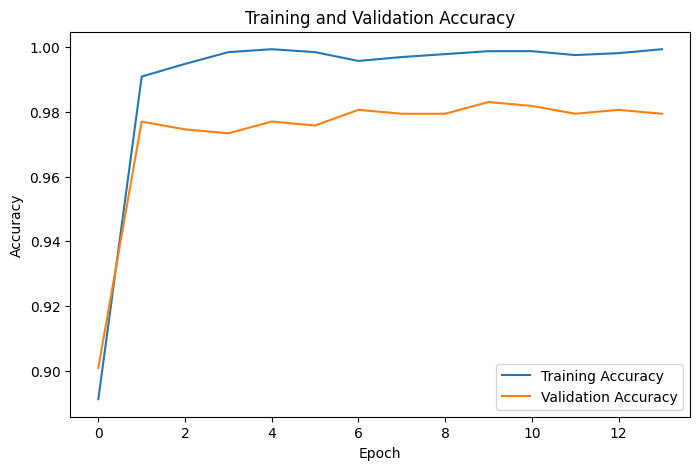

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()

In [21]:
model.load_state_dict(
    torch.load(
        "best_spam_classifier.pth",
        weights_only=True
    )
)

model.eval()

SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.2, inplace=False)
    (11): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [22]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

all_predictions = []
all_actual = []

with torch.no_grad():

    for inputs, labels in test_loader:

        outputs = model(inputs)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).int()

        all_predictions.extend(
            predictions.numpy().flatten()
        )

        all_actual.extend(
            labels.numpy().flatten()
        )

accuracy = accuracy_score(
    all_actual,
    all_predictions
)

print("Test Accuracy:", accuracy)

print("\nClassification Report:")
print(
    classification_report(
        all_actual,
        all_predictions,
        target_names=["Ham", "Spam"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        all_actual,
        all_predictions
    )
)

Test Accuracy: 0.9748549323017408

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.91      0.89      0.90       131

    accuracy                           0.97      1034
   macro avg       0.95      0.94      0.94      1034
weighted avg       0.97      0.97      0.97      1034


Confusion Matrix:
[[892  11]
 [ 15 116]]


In [23]:
sample_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won 50000 rupees. Claim your prize now!",
    "Can you send me the assignment notes?"
]

sample_tfidf = tfidf.transform(sample_messages)

sample_array = sample_tfidf.toarray().astype(np.float32)

sample_tensor = torch.tensor(sample_array)

model.eval()

with torch.no_grad():

    outputs = model(sample_tensor)

    probabilities = torch.sigmoid(outputs).flatten()

for message, probability in zip(
    sample_messages,
    probabilities
):

    confidence = probability.item()

    if confidence >= 0.5:
        prediction = "SPAM"
    else:
        prediction = "HAM"

    print("--------------------------------")
    print("Message:", message)
    print("Prediction:", prediction)
    print("Spam Confidence:", f"{confidence:.2%}")

--------------------------------
Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Spam Confidence: 99.65%
--------------------------------
Message: Hey, are we meeting for lunch today?
Prediction: HAM
Spam Confidence: 0.00%
--------------------------------
Message: URGENT! You have won 50000 rupees. Claim your prize now!
Prediction: SPAM
Spam Confidence: 100.00%
--------------------------------
Message: Can you send me the assignment notes?
Prediction: HAM
Spam Confidence: 0.00%


# Conclusion

This project developed a Deep Learning based SMS Spam Classifier using PyTorch.

The SMS Spam Collection dataset was cleaned and converted into numerical features using TF-IDF vectorization. The data was divided into training, validation, and testing sets to evaluate the model on unseen messages.

A multi-layer neural network was implemented using:
- Linear layers
- ReLU activation
- Batch Normalization
- Dropout regularization
- Adam optimizer
- Binary Cross-Entropy loss

Early stopping was used to reduce overfitting by monitoring validation loss.

The model was evaluated using test accuracy, classification report, and confusion matrix. Training and validation loss and accuracy curves were also plotted.

Finally, the trained model was tested on new SMS messages and produced spam/ham predictions with classification confidence scores.

Overall, the project demonstrates a complete NLP deep learning pipeline from text preprocessing and TF-IDF feature extraction to neural network training, evaluation, and real-world sample inference.